In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from scipy.stats import chi2_contingency, f_oneway

# Load the dataset
df = pd.read_csv("../data/bedtime_screentime_sleep_debt.csv")

# Display first 5 rows
display(df.head())

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


EXPLORATORY DATA ANALYSIS

In [9]:
# ============================================================
# 1. DATASET DIMENSIONS
# ============================================================

print("=== DATASET DIMENSIONS ===")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")


# ============================================================
# 2. DATA TYPES
# ============================================================

print("\n=== DATA TYPES ===")
print(df.dtypes)


# ============================================================
# 3. MISSING VALUES
# ============================================================

print("\n=== MISSING VALUES ===")
print(df.isnull().sum())

print(f"\nTotal missing values: {df.isnull().sum().sum()}")


# ============================================================
# 4. FEATURE DEFINITIONS AND UNITS
# ============================================================

feature_info = {
    "user_id": {
        "definition": "Unique identifier for each user",
        "unit": "ID",
        "role": "Identifier"
    },
    "age": {
        "definition": "Age of the user",
        "unit": "years",
        "role": "Feature"
    },
    "gender": {
        "definition": "Gender category of the user",
        "unit": "categorical",
        "role": "Feature"
    },
    "occupation_type": {
        "definition": "Type of occupation or work arrangement",
        "unit": "categorical",
        "role": "Feature"
    },
    "chronotype": {
        "definition": "User's typical sleep-wake preference",
        "unit": "categorical",
        "role": "Feature"
    },
    "bedtime_phone_minutes": {
        "definition": "Minutes spent using a phone around bedtime",
        "unit": "minutes",
        "role": "Feature"
    },
    "primary_bedtime_app": {
        "definition": "Main application used around bedtime",
        "unit": "categorical",
        "role": "Feature"
    },
    "screen_brightness_pct": {
        "definition": "Screen brightness level during bedtime phone use",
        "unit": "%",
        "role": "Feature"
    },
    "blue_light_filter_active": {
        "definition": "Whether the blue-light filter is active",
        "unit": "0 = No, 1 = Yes",
        "role": "Feature"
    },
    "caffeine_post_5pm_mg": {
        "definition": "Amount of caffeine consumed after 5 PM",
        "unit": "mg",
        "role": "Feature"
    },
    "physical_activity_min": {
        "definition": "Amount of physical activity performed",
        "unit": "minutes",
        "role": "Feature"
    },
    "sleep_latency_min": {
        "definition": "Time required to fall asleep",
        "unit": "minutes",
        "role": "Feature"
    },
    "total_sleep_hours": {
        "definition": "Total amount of sleep obtained",
        "unit": "hours",
        "role": "Feature"
    },
    "deep_sleep_pct": {
        "definition": "Percentage of total sleep spent in deep sleep",
        "unit": "%",
        "role": "Feature"
    },
    "rem_sleep_pct": {
        "definition": "Percentage of total sleep spent in REM sleep",
        "unit": "%",
        "role": "Feature"
    },
    "morning_alarm_snoozes": {
        "definition": "Number of times the morning alarm was snoozed",
        "unit": "count",
        "role": "Feature"
    },
    "next_day_fatigue_score": {
        "definition": "Fatigue level experienced on the following day",
        "unit": "score (0–10)",
        "role": "Feature"
    },
    "sleep_debt_category": {
        "definition": "Category representing the user's sleep debt or recovery status",
        "unit": "categorical",
        "role": "Target"
    }
}

feature_table = pd.DataFrame(feature_info).T

print("\n=== FEATURE DEFINITIONS ===")
display(feature_table)

=== DATASET DIMENSIONS ===
Number of rows: 8500
Number of columns: 18

=== DATA TYPES ===
user_id                         str
age                           int64
gender                          str
occupation_type                 str
chronotype                      str
bedtime_phone_minutes         int64
primary_bedtime_app             str
screen_brightness_pct         int64
blue_light_filter_active      int64
caffeine_post_5pm_mg          int64
physical_activity_min         int64
sleep_latency_min           float64
total_sleep_hours           float64
deep_sleep_pct              float64
rem_sleep_pct               float64
morning_alarm_snoozes         int64
next_day_fatigue_score      float64
sleep_debt_category             str
dtype: object

=== MISSING VALUES ===
user_id                     0
age                         0
gender                      0
occupation_type             0
chronotype                  0
bedtime_phone_minutes       0
primary_bedtime_app         0
screen_brightn

,definition,unit,role
user_id,Unique identifier for each user,ID,Identifier
age,Age of the user,years,Feature
gender,Gender category of the user,categorical,Feature
occupation_type,Type of occupation or work arrangement,categorical,Feature
chronotype,User's typical sleep-wake preference,categorical,Feature
bedtime_phone_minutes,Minutes spent using a phone around bedtime,minutes,Feature
primary_bedtime_app,Main application used around bedtime,categorical,Feature
screen_brightness_pct,Screen brightness level during bedtime phone use,%,Feature
blue_light_filter_active,Whether the blue-light filter is active,"0 = No, 1 = Yes",Feature
caffeine_post_5pm_mg,Amount of caffeine consumed after 5 PM,mg,Feature


In [10]:
# ============================================================
# 5. TARGET LABELS
# ============================================================

print("=== TARGET LABEL ===")

target = "sleep_debt_category"

print(f"Target variable: {target}")
print("\nTarget labels:")

print(df[target].value_counts())

print("\nTarget label percentages:")
print(df[target].value_counts(normalize=True).mul(100).round(2))

=== TARGET LABEL ===
Target variable: sleep_debt_category

Target labels:
sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64

Target label percentages:
sleep_debt_category
Moderate Debt        52.49
Mild Deficit         23.58
Optimal Recovery     16.32
Severe Sleep Debt     7.61
Name: proportion, dtype: float64


DUPLICATE

In [11]:
# ============================================================
# DUPLICATE CHECK
# ============================================================

duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

# Check duplicate user IDs
duplicate_ids = df["user_id"].duplicated().sum()

print("Duplicate user IDs:", duplicate_ids)

Duplicate rows: 0
Duplicate user IDs: 0


CATEGORICAL VALUES CHECK

In [12]:
# ============================================================
# CATEGORICAL CONSISTENCY CHECK
# ============================================================

categorical_columns = [
    "gender",
    "occupation_type",
    "chronotype",
    "primary_bedtime_app",
    "sleep_debt_category"
]

for column in categorical_columns:
    print(f"\n=== {column} ===")

    distribution = pd.DataFrame({
        "Count": df[column].value_counts(),
        "Percentage": df[column].value_counts(normalize=True) * 100
    })

    print(distribution)



=== gender ===
            Count  Percentage
gender                       
Female       4347   51.141176
Male         3905   45.941176
Non-Binary    248    2.917647

=== occupation_type ===
                           Count  Percentage
occupation_type                             
Corporate 9-to-5            2838   33.388235
Remote Tech                 2142   25.200000
Student                     1622   19.082353
Healthcare / Shift Worker    997   11.729412
Freelance / Creative         901   10.600000

=== chronotype ===
              Count  Percentage
chronotype                     
Intermediate   3880   45.647059
Night Owl      2455   28.882353
Morning Lark   2165   25.470588

=== primary_bedtime_app ===
                          Count  Percentage
primary_bedtime_app                        
TikTok / Reels             2198   25.858824
YouTube                    1928   22.682353
Instagram / Reddit         1630   19.176471
Streaming (Netflix/Hulu)   1301   15.305882
Messaging / Chat     

IMPOSSIBLE VALUES CHECK

In [13]:
# ============================================================
# IMPOSSIBLE VALUE CHECK
# ============================================================

range_checks = {
    "age": (18, 65),
    "bedtime_phone_minutes": (0, None),
    "screen_brightness_pct": (0, 100),
    "blue_light_filter_active": (0, 1),
    "caffeine_post_5pm_mg": (0, None),
    "physical_activity_min": (0, None),
    "sleep_latency_min": (0, None),
    "total_sleep_hours": (0, 24),
    "deep_sleep_pct": (0, 100),
    "rem_sleep_pct": (0, 100),
    "morning_alarm_snoozes": (0, None),
    "next_day_fatigue_score": (0, 10)
}

for column, (minimum, maximum) in range_checks.items():

    invalid = pd.Series(False, index=df.index)

    if minimum is not None:
        invalid |= df[column] < minimum

    if maximum is not None:
        invalid |= df[column] > maximum

    print(
        f"{column}: "
        f"{invalid.sum()} impossible values"
    )

age: 0 impossible values
bedtime_phone_minutes: 0 impossible values
screen_brightness_pct: 0 impossible values
blue_light_filter_active: 0 impossible values
caffeine_post_5pm_mg: 0 impossible values
physical_activity_min: 0 impossible values
sleep_latency_min: 0 impossible values
total_sleep_hours: 0 impossible values
deep_sleep_pct: 0 impossible values
rem_sleep_pct: 0 impossible values
morning_alarm_snoozes: 0 impossible values
next_day_fatigue_score: 0 impossible values


DATA QUALITY SUMMARY

In [14]:
# ============================================================
# DATA QUALITY SUMMARY
# ============================================================

quality_summary = pd.DataFrame({
    "Issue": [
        "Missing values",
        "Duplicate rows",
        "Duplicate user IDs",
        "Inconsistent categorical entries",
        "Impossible numerical values"
    ],

    "Result": [
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df["user_id"].duplicated().sum(),
        "None detected",
        "None detected"
    ],

    "Action Taken": [
        "No action required",
        "No rows removed",
        "No IDs removed",
        "No correction required",
        "No values removed or changed"
    ]
})

display(quality_summary)

,Issue,Result,Action Taken
0,Missing values,0,No action required
1,Duplicate rows,0,No rows removed
2,Duplicate user IDs,0,No IDs removed
3,Inconsistent categorical entries,None detected,No correction required
4,Impossible numerical values,None detected,No values removed or changed


SUMMARY STATISTICS

In [15]:
# ============================================================
# SUMMARY STATISTICS
# ============================================================

numeric_columns = df.select_dtypes(include=np.number).columns

summary_statistics = df[numeric_columns].describe().T

display(summary_statistics)

,count,mean,std,min,25%,50%,75%,max
age,8500.0,34.355647,11.584259,18.0,25.00,32.00,42.00,65.0
bedtime_phone_minutes,8500.0,59.250000,36.931991,1.0,31.00,51.00,79.00,180.0
screen_brightness_pct,8500.0,55.153882,19.850550,10.0,42.00,55.00,69.00,100.0
blue_light_filter_active,8500.0,0.467765,0.498989,0.0,0.00,0.00,1.00,1.0
caffeine_post_5pm_mg,8500.0,33.222471,51.935645,0.0,0.00,0.00,55.00,250.0
physical_activity_min,8500.0,35.701412,20.819390,0.0,21.00,35.00,50.00,112.0
sleep_latency_min,8500.0,40.671471,17.444914,6.0,28.20,37.60,49.70,123.3
total_sleep_hours,8500.0,6.266209,1.446258,3.2,5.24,6.33,7.35,9.8
deep_sleep_pct,8500.0,21.735741,3.069377,8.1,19.70,21.90,23.90,28.0
rem_sleep_pct,8500.0,19.105859,2.546459,9.6,17.40,19.10,20.80,27.0


PLOT 1: TARGET DISTRIBUTION

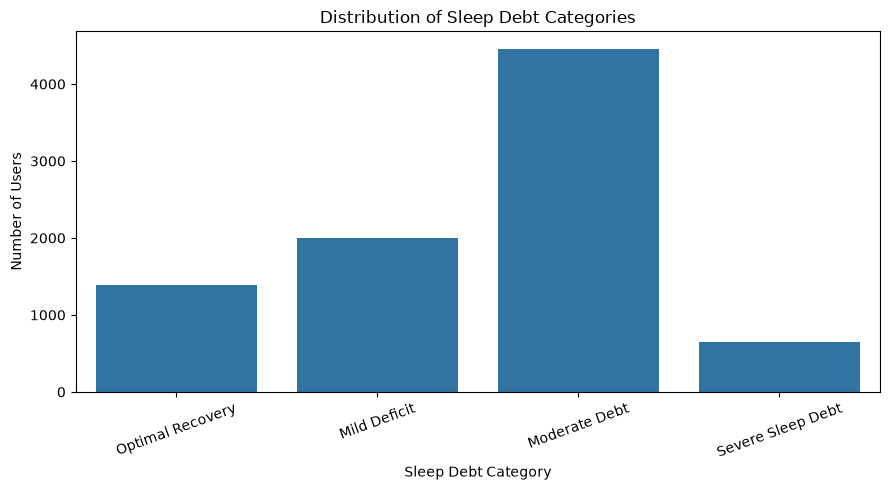

In [16]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="sleep_debt_category",
    order=[
        "Optimal Recovery",
        "Mild Deficit",
        "Moderate Debt",
        "Severe Sleep Debt"
    ]
)

plt.title("Distribution of Sleep Debt Categories")
plt.xlabel("Sleep Debt Category")
plt.ylabel("Number of Users")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

UNIVARIATE DISTRIBUTION OF IMPORTANT FEATURE

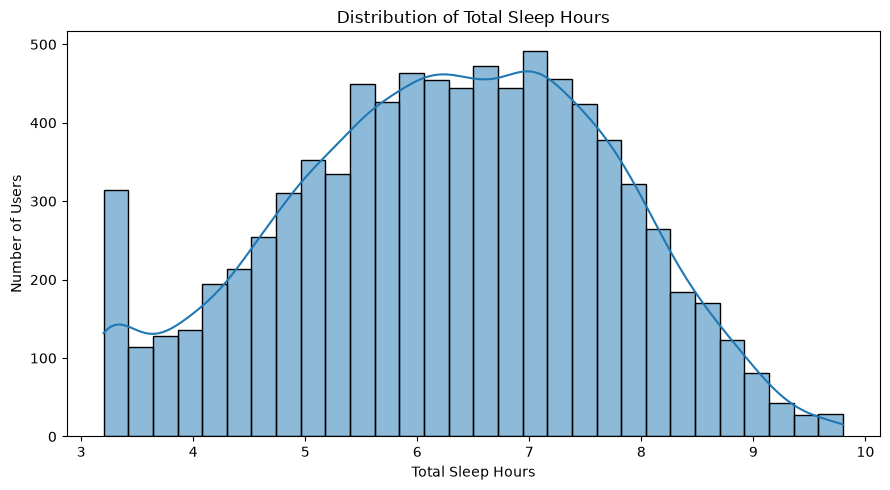

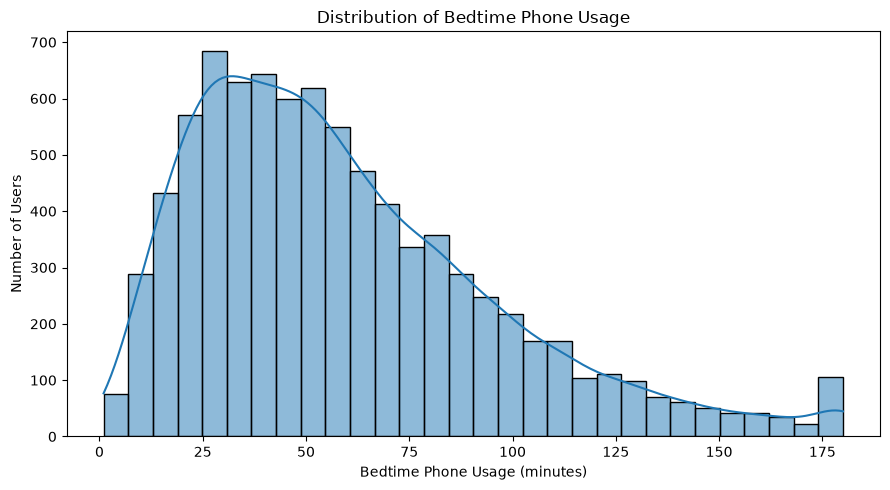

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="total_sleep_hours",
    bins=30,
    kde=True
)

plt.title("Distribution of Total Sleep Hours")
plt.xlabel("Total Sleep Hours")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="bedtime_phone_minutes",
    bins=30,
    kde=True
)

plt.title("Distribution of Bedtime Phone Usage")
plt.xlabel("Bedtime Phone Usage (minutes)")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()

RELATIONSHIP OF FEATURES WITH TARGET

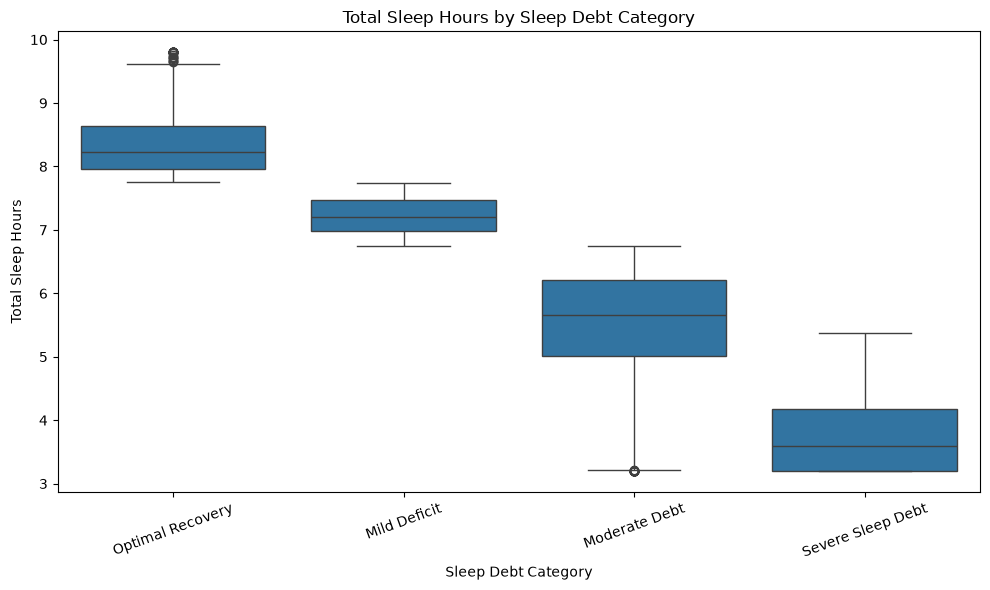

In [18]:
plt.figure(figsize=(10, 6))

order = [
    "Optimal Recovery",
    "Mild Deficit",
    "Moderate Debt",
    "Severe Sleep Debt"
]

sns.boxplot(
    data=df,
    x="sleep_debt_category",
    y="total_sleep_hours",
    order=order
)

plt.title("Total Sleep Hours by Sleep Debt Category")
plt.xlabel("Sleep Debt Category")
plt.ylabel("Total Sleep Hours")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

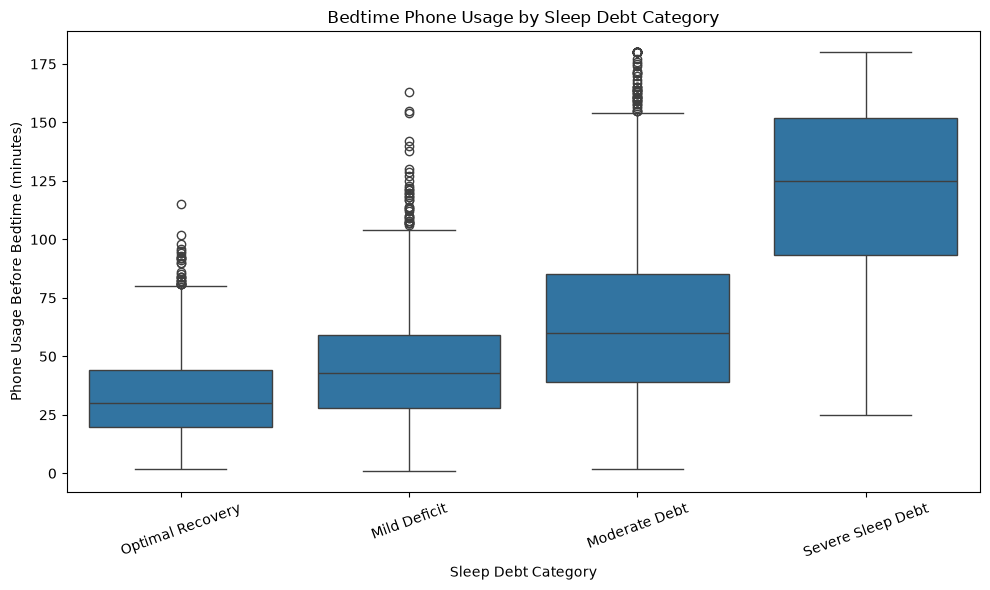

In [19]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="sleep_debt_category",
    y="bedtime_phone_minutes",
    order=order
)

plt.title("Bedtime Phone Usage by Sleep Debt Category")
plt.xlabel("Sleep Debt Category")
plt.ylabel("Phone Usage Before Bedtime (minutes)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

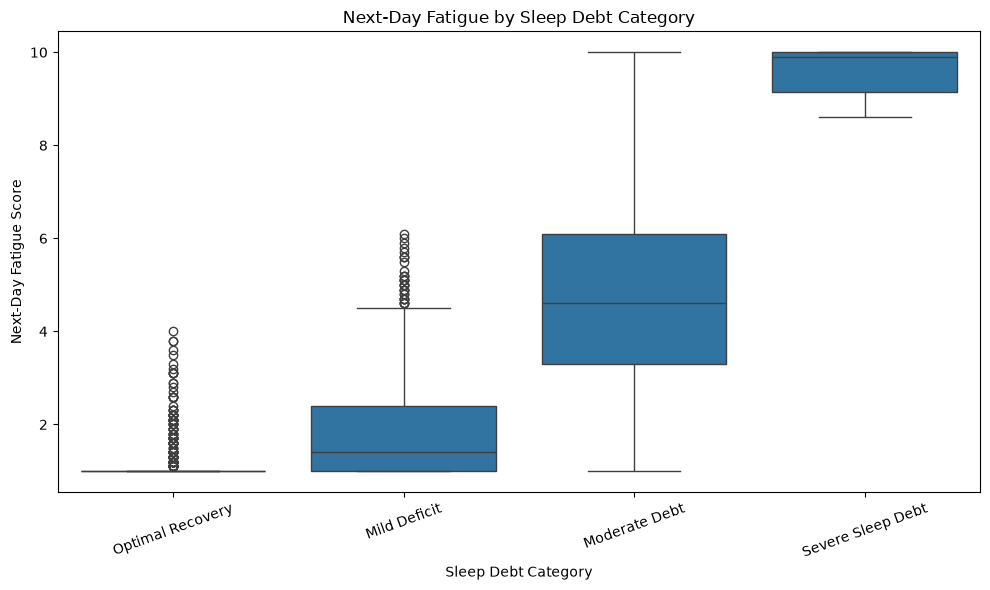

In [20]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="sleep_debt_category",
    y="next_day_fatigue_score",
    order=order
)

plt.title("Next-Day Fatigue by Sleep Debt Category")
plt.xlabel("Sleep Debt Category")
plt.ylabel("Next-Day Fatigue Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

NUMERICAL FEATURES CORRELATION WITH TARGET

In [21]:
# ============================================================
# SPEARMAN CORRELATION WITH ORDERED TARGET
# ============================================================

target_order = {
    "Optimal Recovery": 0,
    "Mild Deficit": 1,
    "Moderate Debt": 2,
    "Severe Sleep Debt": 3
}

df["target_numeric"] = df["sleep_debt_category"].map(target_order)

numeric_features = [
    "age",
    "bedtime_phone_minutes",
    "screen_brightness_pct",
    "caffeine_post_5pm_mg",
    "physical_activity_min",
    "sleep_latency_min",
    "total_sleep_hours",
    "deep_sleep_pct",
    "rem_sleep_pct",
    "morning_alarm_snoozes",
    "next_day_fatigue_score"
]

spearman_results = []

for feature in numeric_features:

    correlation = df[feature].corr(
        df["target_numeric"],
        method="spearman"
    )

    spearman_results.append({
        "Feature": feature,
        "Spearman Correlation": correlation
    })

spearman_df = pd.DataFrame(spearman_results)

spearman_df = (
    spearman_df
    .sort_values(
        "Spearman Correlation",
        key=abs,
        ascending=False
    )
)

display(spearman_df.round(3))
plt.show()

,Feature,Spearman Correlation
6,total_sleep_hours,-0.907
10,next_day_fatigue_score,0.831
9,morning_alarm_snoozes,0.763
1,bedtime_phone_minutes,0.507
5,sleep_latency_min,0.490
7,deep_sleep_pct,-0.177
3,caffeine_post_5pm_mg,0.049
8,rem_sleep_pct,-0.040
2,screen_brightness_pct,0.035
0,age,-0.020


CATEGORICAL FEATURES ASSOCIATION WITH TARGET


In [22]:
# ============================================================
# CATEGORICAL ASSOCIATION WITH TARGET
# ============================================================

categorical_features = [
    "gender",
    "occupation_type",
    "chronotype",
    "primary_bedtime_app",
    "blue_light_filter_active"
]

association_results = []

for feature in categorical_features:

    contingency_table = pd.crosstab(
        df[feature],
        df["sleep_debt_category"]
    )

    chi2, p, dof, expected = chi2_contingency(
        contingency_table
    )

    n = contingency_table.values.sum()
    rows, cols = contingency_table.shape

    cramer_v = np.sqrt(
        (chi2 / n) /
        min(rows - 1, cols - 1)
    )

    association_results.append({
        "Feature": feature,
        "Chi-square p-value": p,
        "Cramer's V": cramer_v,
        "Significant (p < 0.05)": p < 0.05
    })

association_df = pd.DataFrame(association_results)

display(association_df)

,Feature,Chi-square p-value,Cramer's V,Significant (p < 0.05)
0,gender,6.357678e-01,0.015909,False
1,occupation_type,8.430653e-101,0.140959,True
2,chronotype,0.000000e+00,0.410585,True
3,primary_bedtime_app,3.388113e-07,0.048204,True
4,blue_light_filter_active,3.736867e-06,0.057334,True


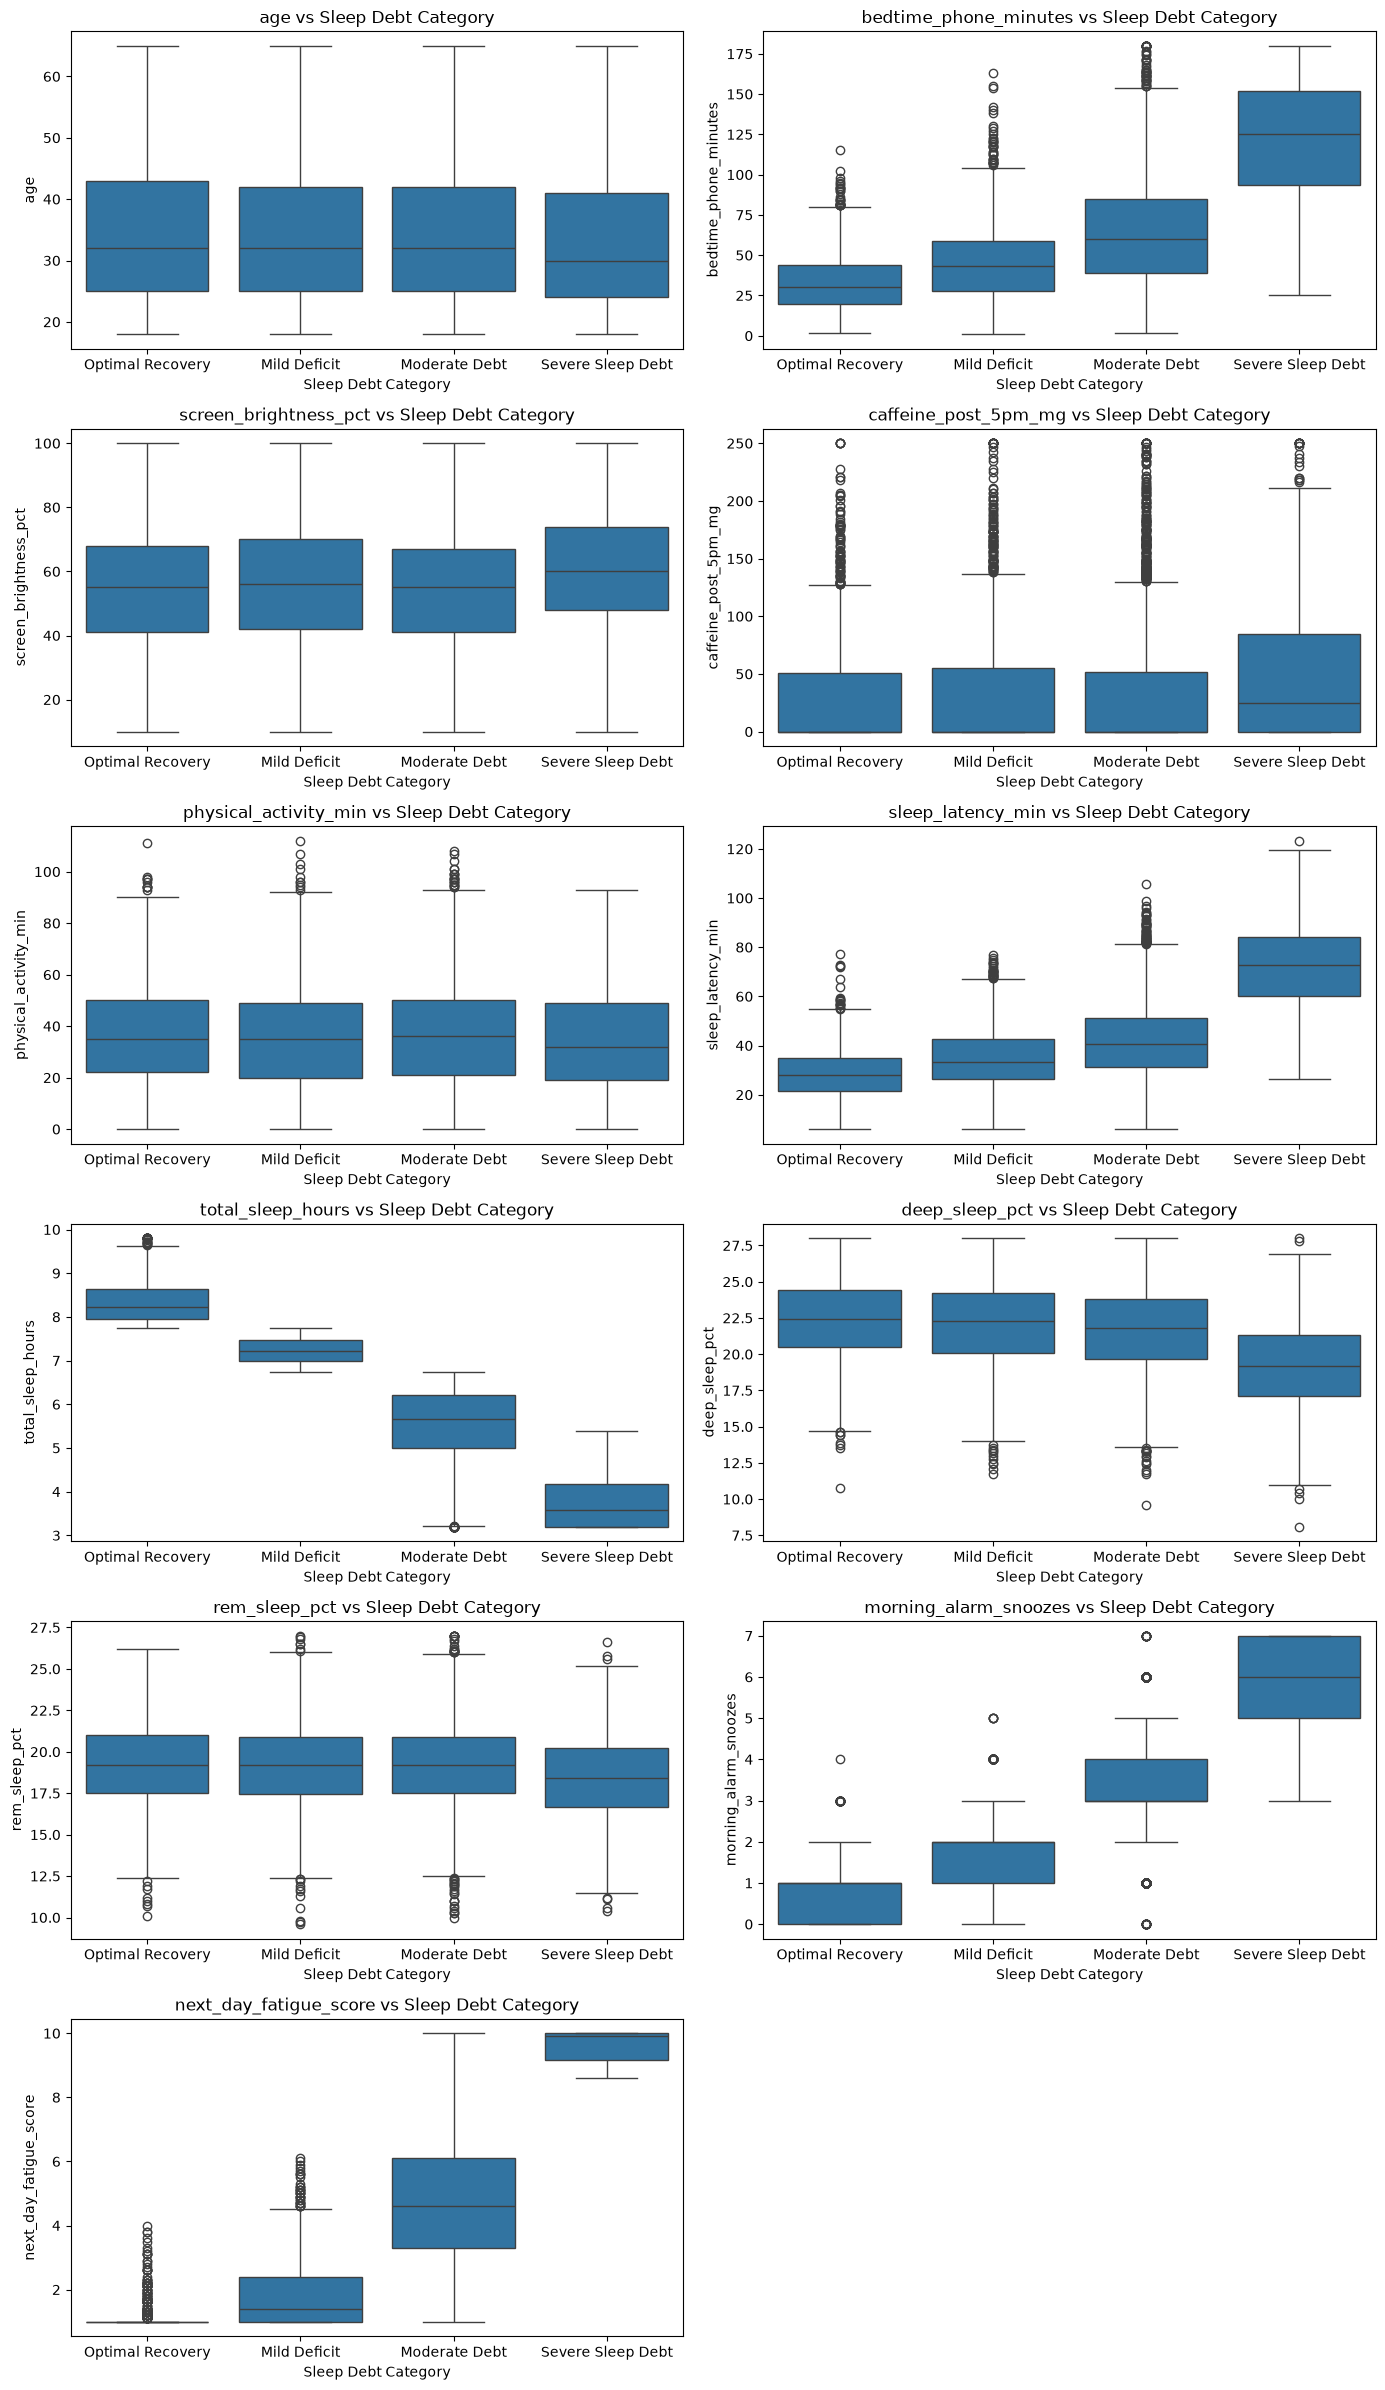

In [26]:
n_cols = 2
n_rows = int(np.ceil(len(numeric_features) / n_cols))

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(14, 4 * n_rows)
)

# Flatten axes for easy iteration
axes = np.array(axes).flatten()

for ax, feature in zip(axes, numeric_features):
    sns.boxplot(
        data=df,
        x="sleep_debt_category",
        y=feature,
        order=order,
        ax=ax
    )

    ax.set_title(f"{feature} vs Sleep Debt Category")
    ax.set_xlabel("Sleep Debt Category")
    ax.set_ylabel(feature)

# Hide unused subplots
for ax in axes[len(numeric_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

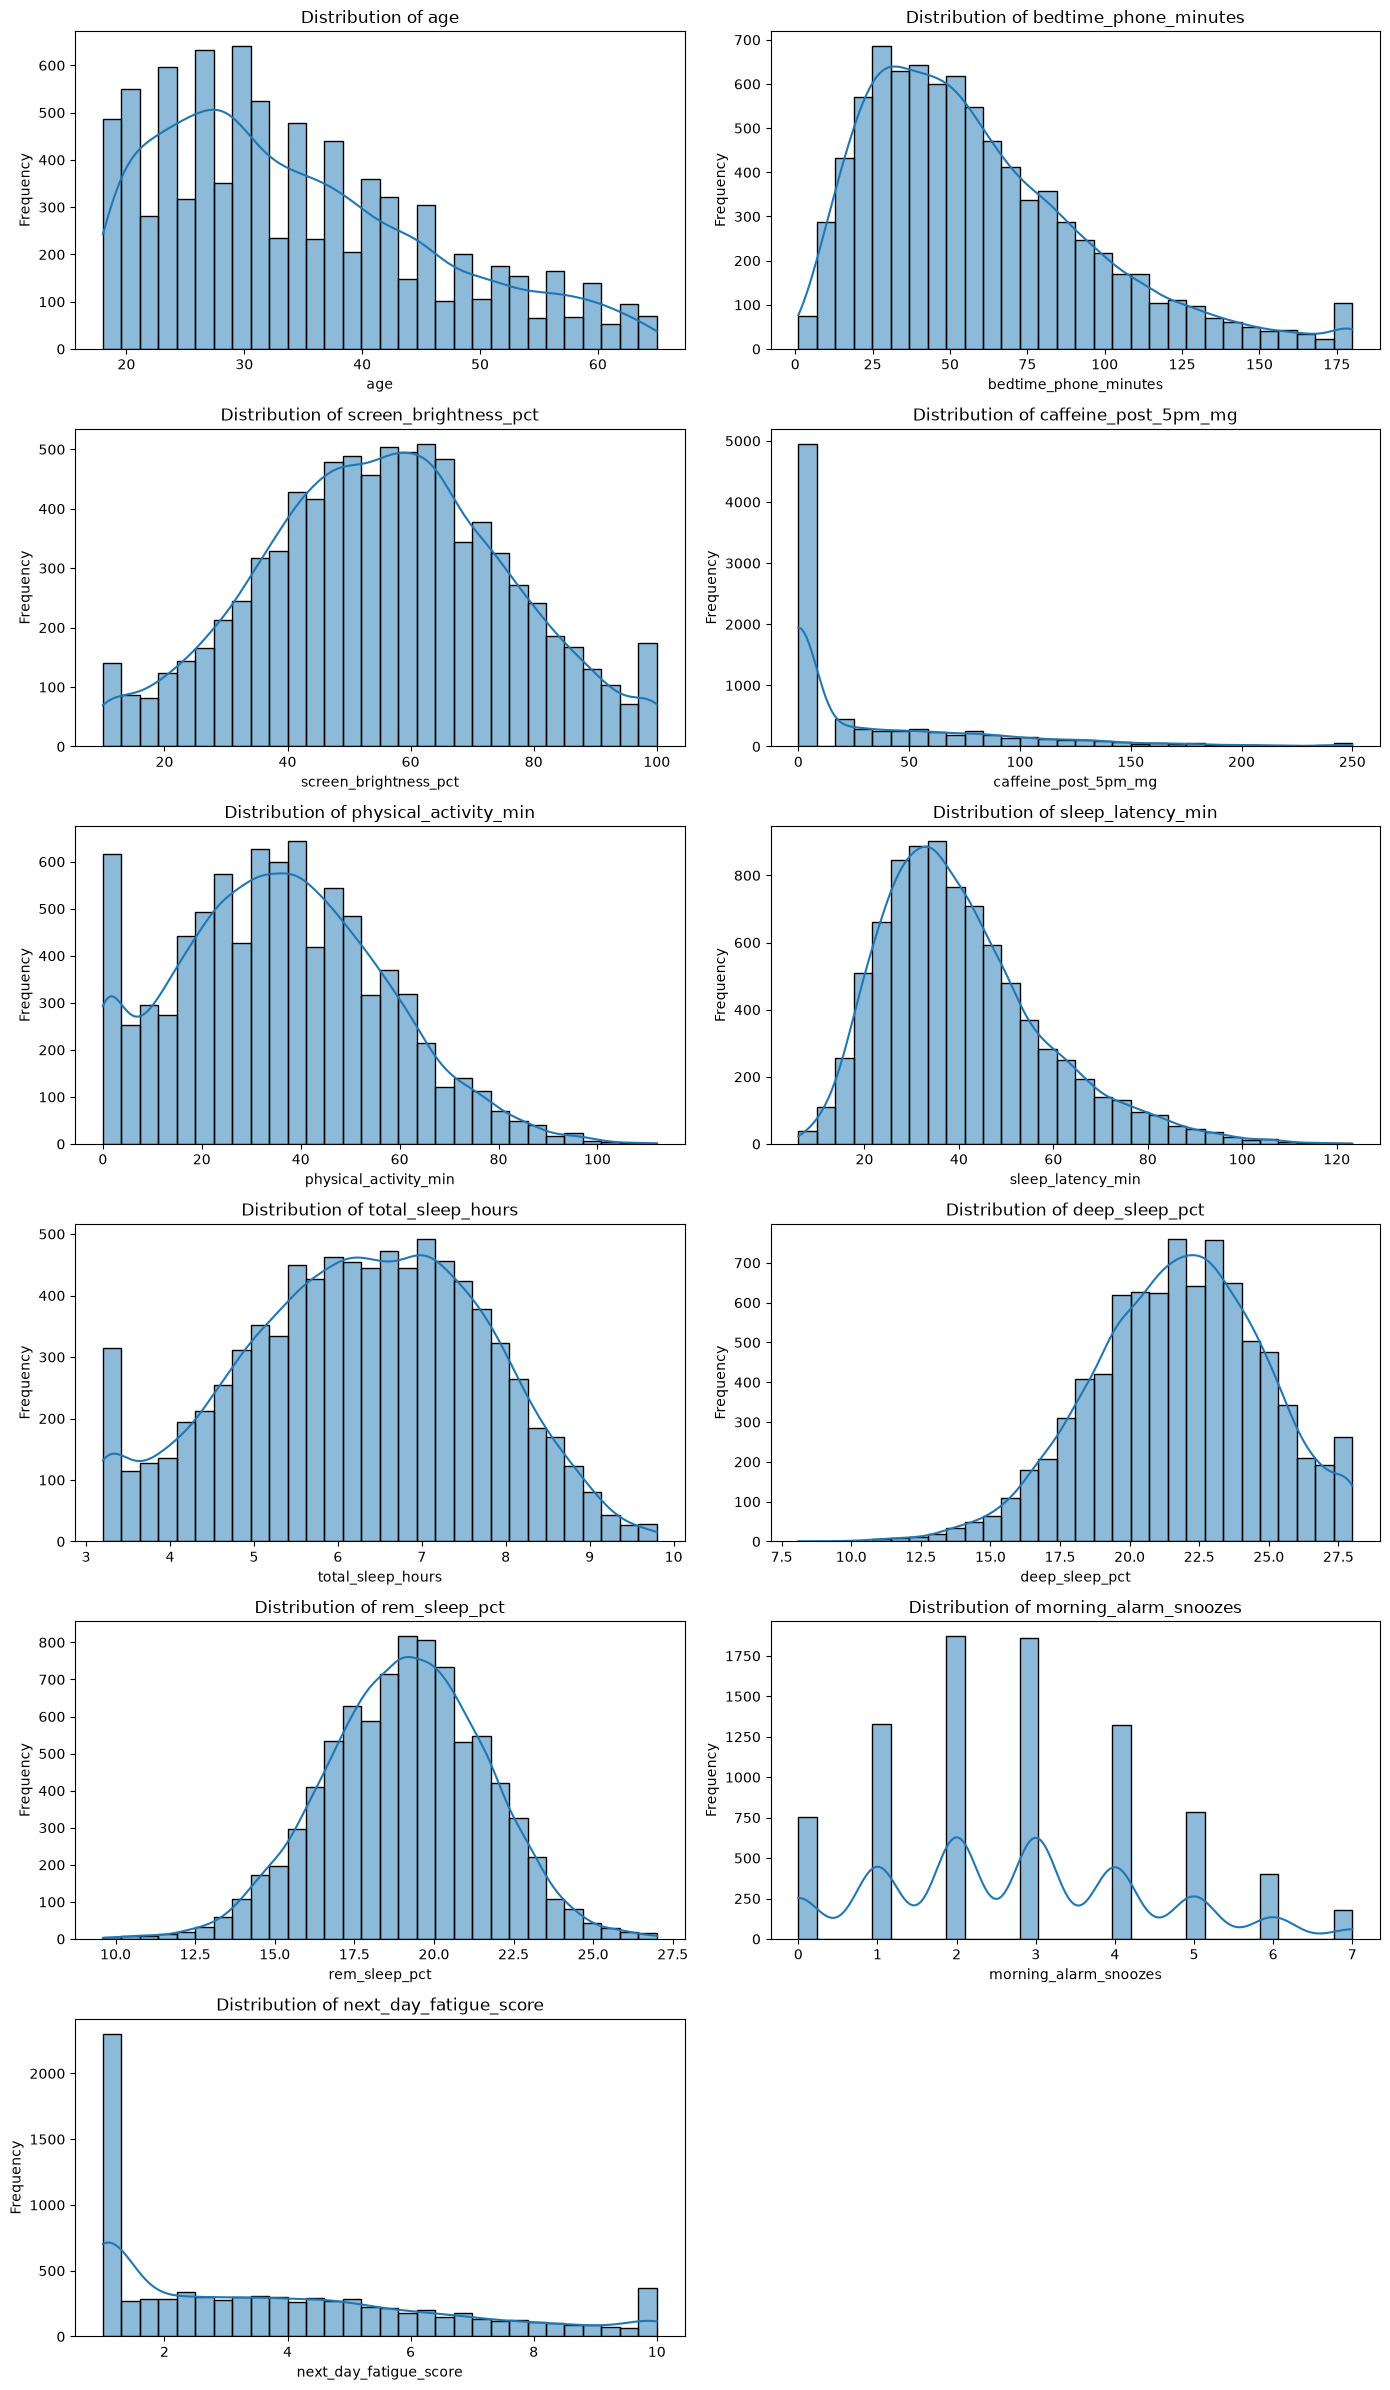

In [25]:
# Set up a grid with 2 columns
n_cols = 2
n_rows = int(np.ceil(len(numeric_features) / n_cols))

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(14, 4 * n_rows)
)

# Flatten axes for easy iteration
axes = np.array(axes).flatten()

for ax, feature in zip(axes, numeric_features):
    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

# Hide unused subplots
for ax in axes[len(numeric_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()